In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import arviz as az
import bambi as bmb
from scipy.stats import binom
from matplotlib.ticker import MultipleLocator
from matplotlib.patches import Patch
import re
from rapidfuzz import fuzz


In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

HOOFDKLEUR = '#007044'
PALET = ['#0067B9', '#FF9527', '#E100A3', '#9569BE', '#007044', '#00859B', '#CC982F',
         '#F275D4', '#59C0D1', '#4A5B84', '#FFD200', '#1A915E', '#27376B']

plt.rcParams.update({
    'font.family': 'Libertinus Serif',
    'font.size': CORPS,
    
    'axes.titlesize': CORPS,
    'axes.labelsize': CORPS,
    'xtick.labelsize': CORPS,
    'ytick.labelsize': CORPS,
    'legend.fontsize': CORPS,
    
    'figure.figsize': (TEKSTBREEDTE, TEKSTBREEDTE * 0.66),
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
map_macro = Path("../../data/algemeen/gebeurtenisdata_macro")
excel_files = sorted([f for f in map_macro.glob("*.xlsx")])

print(len(excel_files))

dataframes = []
for file in excel_files:
    try:
        df = pd.read_excel(file)
        dataframes.append(df)
    except Exception as e:
        print(file.name)

df_macro = pd.concat(dataframes, ignore_index=True)


198
._MA#30830.xlsx


In [4]:
df_geluid = pd.read_excel("../../data/H8/geluidsoverlast_macro.xlsx")

In [5]:
df_geluid.columns

Index(['archive_file', 'year', 'district', 'Person ID', 'Incident Number',
       'Page Number', 'E_DATE', 'E_TIME', 'E_LOC', 'P_LASTNAME', 'P_FIRSTNAME',
       'P_PROF', 'P_BIRTHPLACE', 'P_BIRTHDATE', 'P_RES', 'P_TITLE',
       'P_MARITALSTATUS', 'P_AGE', 'E_DATE_clean', 'E_TIME_clean',
       'E_TIME_grouped', 'E_LOC_gis1898', 'E_LOC_lat', 'E_LOC_long',
       'firstname_firstword', 'gender_inferred', 'firstname_match',
       'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass', 'E_YEAR',
       'P_AGE_clean', 'P_BIRTHYEAR', 'P_AGE_categories', 'P_BIRTHPLACE_extra',
       'P_BIRTHPLACE_cleaned', 'P_BIRTHPLACE_match', 'P_BIRTHPLACE_country',
       'P_BIRTHPLACE_dis', 'P_BIRTHPLACE_sim', 'astronomical_category', 'text',
       'geluidsoverlast', 'bronbestand'],
      dtype='object')

In [6]:
df_macro = df_macro[df_macro['year'] <= 1939].copy()
df_geluid = df_geluid[df_geluid['year'] <= 1939].copy()

In [7]:
merge_keys = ['archive_file', 'Incident Number']
geluid_incidents = set(zip(df_geluid['archive_file'], df_geluid['Incident Number']))

df_macro['is_geluid'] = df_macro.apply(
    lambda row: 1 if (row['archive_file'], row['Incident Number']) in geluid_incidents else 0,
    axis=1
)

In [8]:
df_unique = df_macro.drop_duplicates(subset=merge_keys)

In [9]:
df_valid = df_unique[
    (df_unique['astro'].notna()) & 
    (df_unique['astro'] != 'unknown')
].copy()

totaal_uniek = len(df_unique)
met_dag_nacht = len(df_valid)
zonder_dag_nacht = totaal_uniek - met_dag_nacht

In [10]:
nacht_cats = ['nacht', 'avondschemering', 'ochtendschemering']
df_nacht = df_valid[df_valid['astro'].isin(nacht_cats)]
df_dag = df_valid[~df_valid['astro'].isin(nacht_cats)]

n_geluid_nacht = df_nacht['is_geluid'].sum()
n_total_nacht = len(df_nacht)
pct_nacht = (n_geluid_nacht / n_total_nacht * 100)

n_geluid_dag = df_dag['is_geluid'].sum()
n_total_dag = len(df_dag)
pct_dag = (n_geluid_dag / n_total_dag * 100)

print(f"Nacht: {n_geluid_nacht}/{n_total_nacht} = {pct_nacht:.1f}%")
print(f"Dag:   {n_geluid_dag}/{n_total_dag} = {pct_dag:.1f}%")
print(f"Zonder dag/nacht info: {zonder_dag_nacht:,}")

Nacht: 1705/31673 = 5.4%
Dag:   486/48254 = 1.0%
Zonder dag/nacht info: 77,738


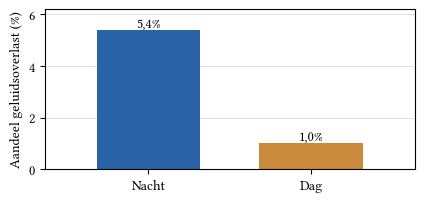

In [11]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.5))

categories = ['Nacht', 'Dag']
percentages = [pct_nacht, pct_dag]
colors = [KLEUR_NACHT, KLEUR_DAG]
x = [0, 0.55]

bars = ax.bar(x, percentages, color=colors, width=0.35)

ax.set_xticks(x)
ax.set_xticklabels(['Nacht', 'Dag'])
ax.set_xlim(-0.35, 0.90)

for bar, pct in zip(bars, percentages):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{pct:.1f}%'.replace('.', ','),
            ha='center', va='bottom', fontsize=CORPS)

ax.set_ylabel('Aandeel geluidsoverlast (%)', fontsize=CORPS)
ax.set_ylim(0, max(percentages) * 1.15)
ax.grid(axis='y')
ax.set_axisbelow(True)

plt.tight_layout()
pas_breedte_aan(plt.gcf(), tight=True)
plt.savefig('../../fig/H8/8.5_dag_nacht.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
df_valid['hour'] = pd.to_datetime(df_valid['E_TIME_clean'], format='%H:%M', errors='coerce').dt.hour

print(df_valid['hour'].value_counts().sort_index())
print(f"Events met geldige uur: {df_valid['hour'].notna().sum():,}")

hour
0      3352
1      3323
2      2564
3      1653
4      1043
5       860
6      1006
7      1180
8      1680
9     11447
10     3557
11     4570
12     3122
13     2827
14     4096
15     6106
16     3894
17     3638
18     3751
19     3677
20     3684
21     4439
22     2487
23     1971
Name: count, dtype: int64
Events met geldige uur: 79,927


In [13]:
# CEL: Check uren per astronomische categorie
for cat in ['nacht', 'avondschemering', 'ochtendschemering']:
    df_cat = df_valid[df_valid['astro'] == cat]
    if len(df_cat) > 0:
        min_uur = df_cat['hour'].min()
        max_uur = df_cat['hour'].max()
        print(f"{cat}: {min_uur:02d}u - {max_uur:02d}u")

nacht: 00u - 23u
avondschemering: 15u - 21u
ochtendschemering: 02u - 08u


In [14]:
nacht_uren = [15, 16, 17, 18, 19, 20, 21, 22, 23, 0, 1, 2, 3, 4, 5, 6, 7, 8]
df_nacht_uren = df_valid[df_valid['hour'].isin(nacht_uren)].copy()

print(f"geb 15u-8u: {len(df_nacht_uren):,}")

geb 15u-8u: 50,308


In [15]:
per_uur = []
for uur in sorted(nacht_uren):
    df_uur = df_nacht_uren[df_nacht_uren['hour'] == uur]
    n_geluid = df_uur['is_geluid'].sum()
    n_totaal = len(df_uur)
    pct = (n_geluid / n_totaal * 100) if n_totaal > 0 else 0
    per_uur.append({
        'hour': uur,
        'geluid': n_geluid,
        'totaal': n_totaal,
        'pct': pct
    })

df_per_uur = pd.DataFrame(per_uur)
print(df_per_uur)

    hour  geluid  totaal        pct
0      0     377    3352  11.247017
1      1     432    3323  13.000301
2      2     326    2564  12.714509
3      3     221    1653  13.369631
4      4      84    1043   8.053691
5      5      27     860   3.139535
6      6      18    1006   1.789264
7      7      14    1180   1.186441
8      8      22    1680   1.309524
9     15      55    6106   0.900753
10    16      28    3894   0.719055
11    17      18    3638   0.494777
12    18      32    3751   0.853106
13    19      40    3677   1.087843
14    20      43    3684   1.167210
15    21      56    4439   1.261545
16    22      46    2487   1.849618
17    23      50    1971   2.536783


In [16]:
nacht_uren_sorted = [15, 16, 17, 18, 19, 20, 21, 22, 23, 0, 1, 2, 3, 4, 5, 6, 7, 8]
df_per_uur['hour'] = pd.Categorical(df_per_uur['hour'], categories=nacht_uren_sorted, ordered=True)
df_per_uur = df_per_uur.sort_values('hour')

print(df_per_uur)

   hour  geluid  totaal        pct
9    15      55    6106   0.900753
10   16      28    3894   0.719055
11   17      18    3638   0.494777
12   18      32    3751   0.853106
13   19      40    3677   1.087843
14   20      43    3684   1.167210
15   21      56    4439   1.261545
16   22      46    2487   1.849618
17   23      50    1971   2.536783
0     0     377    3352  11.247017
1     1     432    3323  13.000301
2     2     326    2564  12.714509
3     3     221    1653  13.369631
4     4      84    1043   8.053691
5     5      27     860   3.139535
6     6      18    1006   1.789264
7     7      14    1180   1.186441
8     8      22    1680   1.309524


In [17]:
print(df_macro.columns.tolist())

['bron', 'archive_file', 'year', 'district', 'Person ID', 'Incident Number', 'Page Number', 'E_DATE', 'E_TIME', 'E_LOC', 'P_LASTNAME', 'P_FIRSTNAME', 'P_PROF', 'P_BIRTHPLACE', 'P_BIRTHDATE', 'P_RES', 'P_TITLE', 'P_MARITALSTATUS', 'P_AGE', 'E_DATE_clean', 'E_TIME_clean', 'E_TIME_grouped', 'E_LOC_gis1898', 'firstname_firstword', 'gender_inferred', 'firstname_match', 'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass', 'E_YEAR', 'P_AGE_clean', 'P_BIRTHYEAR', 'P_AGE_categories', 'P_BIRTHPLACE_extra', 'P_BIRTHPLACE_cleaned', 'P_BIRTHPLACE_match', 'P_BIRTHPLACE_country', 'P_BIRTHPLACE_dis', 'P_BIRTHPLACE_sim', 'astro', 'incident_text', 'E_LOC_gis1898_oud', 'is_geluid']


In [18]:
# Is er uurinformatie beschikbaar?
df_macro["uur_bekend"] = (
    df_macro["E_TIME_clean"].notna()
    & df_macro["E_TIME_clean"].astype(str).str.strip().ne("")
)

print(df_macro["uur_bekend"].value_counts())
print(df_macro["uur_bekend"].value_counts(normalize=True) * 100)

uur_bekend
True     256661
False    108803
Name: count, dtype: int64
uur_bekend
True     70.228805
False    29.771195
Name: proportion, dtype: float64


In [19]:

# Absolute aantallen
print(pd.crosstab(
    df_macro["is_geluid"],
    df_macro["uur_bekend"]
))

# Percentages BINNEN geluid / geen geluid
print(pd.crosstab(
    df_macro["is_geluid"],
    df_macro["uur_bekend"],
    normalize="index"
) * 100)

uur_bekend   False   True 
is_geluid                 
0           107319  249943
1             1484    6718


uur_bekend      False      True 
is_geluid                       
0           30.039299  69.960701
1           18.093148  81.906852

In [20]:
missing_jaar = (
    df_macro
    .groupby(["year", "is_geluid"])["uur_bekend"]
    .mean()
    .mul(100)
    .unstack()
)

missing_jaar.columns = ["geen_geluid", "geluid"]

print(missing_jaar.round(1).to_string())

      geen_geluid  geluid
year                     
1876         96.6    97.8
1877         83.0    96.6
1878         82.9    91.6
1879         54.5    88.9
1880         81.3    96.3
1881         76.0    97.8
1882         70.5    95.5
1883         80.1    83.8
1884         81.4    97.2
1885         79.4    91.0
1886         82.6    91.8
1887         82.1    93.2
1888         85.0    94.3
1889         83.0    93.2
1890         83.6    92.3
1891         76.0    92.8
1892         66.5    98.9
1893         78.6    97.0
1894         81.5   100.0
1895         39.0    72.2
1896         59.8    85.6
1899         93.1    93.9
1900         85.5    90.3
1901         55.6   100.0
1902         58.6    93.1
1903         57.6    77.4
1904         66.7   100.0
1905         71.8    88.4
1907         55.0    87.5
1908         58.4    97.8
1909         75.6   100.0
1910         38.9    46.0
1911         40.9    47.6
1912         46.2    56.5
1913         49.3    56.7
1914         81.0    95.2
1919        

In [21]:
controle_jaar = (
    df_macro
    .groupby(["year", "is_geluid"])
    .agg(
        n=("uur_bekend", "size"),
        n_uur_bekend=("uur_bekend", "sum"),
        pct_uur_bekend=("uur_bekend", "mean")
    )
    .reset_index()
)

controle_jaar["pct_uur_bekend"] *= 100

print(
    controle_jaar[controle_jaar["is_geluid"] == 1]
    [["year", "n", "n_uur_bekend", "pct_uur_bekend"]]
    .to_string(index=False)
)

 year   n  n_uur_bekend  pct_uur_bekend
 1876 493           482       97.768763
 1877  59            57       96.610169
 1878 308           282       91.558442
 1879  27            24       88.888889
 1880 189           182       96.296296
 1881  89            87       97.752809
 1882 201           192       95.522388
 1883 117            98       83.760684
 1884 108           105       97.222222
 1885  89            81       91.011236
 1886 134           123       91.791045
 1887 147           137       93.197279
 1888  87            82       94.252874
 1889 161           150       93.167702
 1890 155           143       92.258065
 1891 209           194       92.822967
 1892  91            90       98.901099
 1893 100            97       97.000000
 1894  22            22      100.000000
 1895  36            26       72.222222
 1896  97            83       85.567010
 1899  82            77       93.902439
 1900 103            93       90.291262
 1901  16            16      100.000000


In [22]:
# Zelfde uren als oorspronkelijke analyse
nacht_uren = [
    15, 16, 17, 18, 19, 20, 21, 22, 23,
    0, 1, 2, 3, 4, 5, 6, 7, 8
]

# df_valid is reeds:
# 1. gededupliceerd op archive_file + Incident Number
# 2. beperkt tot gebeurtenissen met geldige astro-informatie

d_hier = df_valid.copy()

# Genormaliseerde HH:MM naar uur
mask_tijd = d_hier["E_TIME_clean"].astype(str).str.match(
    r"^\d{2}:\d{2}$"
)
d_hier = d_hier[mask_tijd].copy()
d_hier["uur"] = d_hier["E_TIME_clean"].str[:2].astype(int)

# Exact hetzelfde uurvenster
d_hier = d_hier[d_hier["uur"].isin(nacht_uren)].copy()

print("Totaal gebeurtenissen:", len(d_hier))
print("Totaal geluid:", d_hier["is_geluid"].sum())

Totaal gebeurtenissen: 50308
Totaal geluid: 1889


In [23]:
d_jaar_uur = (
    d_hier
    .groupby(["year", "uur"])
    .agg(
        k=("is_geluid", "sum"),
        n=("is_geluid", "size")
    )
    .reset_index()
)

d_jaar_uur["uur"] = d_jaar_uur["uur"].astype("category")
d_jaar_uur["year"] = d_jaar_uur["year"].astype("category")

print("Jaar-uur-combinaties:", len(d_jaar_uur))
print("Totaal gebeurtenissen:", d_jaar_uur["n"].sum())
print("Totaal geluid:", d_jaar_uur["k"].sum())

Jaar-uur-combinaties: 1024
Totaal gebeurtenissen: 50308
Totaal geluid: 1889


In [24]:
model_h = bmb.Model(
    "p(k, n) ~ 0 + uur + (1|year)",
    d_jaar_uur,
    family="binomial"
)

idata_h = model_h.fit(
    draws=1000,
    tune=1000,
    chains=4,
    cores=2,
    random_seed=42
)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [uur, 1|year_sigma, 1|year_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.


In [25]:
az.summary(idata_h, kind="diagnostics").to_string()

'              mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat\nuur[0]            0.004    0.003     458.0     918.0   1.01\nuur[1]            0.004    0.003     459.0     876.0   1.01\nuur[2]            0.004    0.003     521.0     812.0   1.01\nuur[3]            0.004    0.003     566.0    1146.0   1.01\nuur[4]            0.005    0.003     861.0    1887.0   1.00\nuur[5]            0.004    0.003    2218.0    2315.0   1.00\nuur[6]            0.005    0.004    2275.0    2783.0   1.00\nuur[7]            0.006    0.005    2005.0    2207.0   1.00\nuur[8]            0.005    0.003    2321.0    2678.0   1.00\nuur[15]           0.004    0.003    1199.0    2202.0   1.00\nuur[16]           0.004    0.003    2300.0    2537.0   1.00\nuur[17]           0.005    0.004    2385.0    2569.0   1.00\nuur[18]           0.004    0.003    1830.0    2412.0   1.00\nuur[19]           0.004    0.003    1462.0    2119.0   1.00\nuur[20]           0.004    0.003    1464.0    2446.0   1.00\nuur[21]           0.005

In [26]:
post = idata_h.posterior["uur"]

resultaten_h = []

for uur in [15,16,17,18,19,20,21,22,23,0,1,2,3,4,5,6,7,8]:
    x = post.sel(uur_dim=str(uur)).values.flatten()
    p = 1 / (1 + np.exp(-x))

    resultaten_h.append({
        "uur": uur,
        "gemiddelde": p.mean() * 100,
        "onder": np.quantile(p, 0.03) * 100,
        "boven": np.quantile(p, 0.97) * 100
    })

resultaten_h = pd.DataFrame(resultaten_h)


In [27]:
df_miss = df_unique.copy()

df_miss["tijd_bekend"] = (
    df_miss["E_TIME_clean"]
    .astype(str)
    .str.match(r"^\d{2}:\d{2}$")
)

print("Totaal:", len(df_miss))
print("\nAlgemeen:")
print(
    df_miss["tijd_bekend"]
    .value_counts()
)
print(
    df_miss["tijd_bekend"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print("\nNaar geluidsoverlast:")
tab = pd.crosstab(
    df_miss["is_geluid"],
    df_miss["tijd_bekend"]
)

print(tab)

print("\nRijpercentages:")
print(
    pd.crosstab(
        df_miss["is_geluid"],
        df_miss["tijd_bekend"],
        normalize="index"
    ).mul(100).round(1)
)

Totaal: 157665

Algemeen:
tijd_bekend
True     79984
False    77681
Name: count, dtype: int64
tijd_bekend
True     50.7
False    49.3
Name: proportion, dtype: float64

Naar geluidsoverlast:
tijd_bekend  False  True 
is_geluid                
0            76785  77790
1              896   2194

Rijpercentages:
tijd_bekend  False  True 
is_geluid                
0             49.7   50.3
1             29.0   71.0


In [28]:
miss_jaar = (
    df_miss
    .groupby(["year", "is_geluid"])["tijd_bekend"]
    .agg(["count", "mean"])
    .reset_index()
)

miss_jaar["pct_tijd_bekend"] = miss_jaar["mean"] * 100

overzicht = miss_jaar.pivot(
    index="year",
    columns="is_geluid",
    values="pct_tijd_bekend"
)

overzicht.columns = ["geen_geluid", "geluid"]
print(overzicht.round(1).to_string())

      geen_geluid  geluid
year                     
1876         49.1    55.6
1877         49.4    60.6
1878         38.6    48.0
1879         44.1    59.1
1880         47.9    62.8
1881         41.4    68.9
1882         43.2    72.2
1883         49.9    53.3
1884         49.5    64.7
1885         46.6    63.6
1886         53.6    72.9
1887         58.1    78.9
1888         60.4    65.1
1889         61.3    77.5
1890         63.3    80.0
1891         63.5    86.5
1892         51.6    92.0
1893         66.5    92.6
1894         53.8    54.5
1895         13.6    33.3
1896         41.6    76.9
1899         78.3    85.0
1900         75.3    85.0
1901         24.4    37.5
1902         39.9    80.0
1903         37.1    58.8
1904         44.0    81.2
1905         54.9    65.4
1907         25.5    50.0
1908         50.9    95.7
1909         68.8    92.3
1910         24.2    40.7
1911         24.0    39.7
1912         35.7    58.0
1913         45.2    68.6
1914         73.5    90.0
1919        

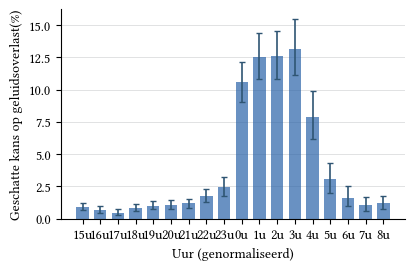

In [29]:
uren = [15, 16, 17, 18, 19, 20, 21, 22, 23,
        0, 1, 2, 3, 4, 5, 6, 7, 8]

# Zet resultaten in de juiste volgorde
plot_df = (
    resultaten_h
    .set_index("uur")
    .loc[uren]
    .reset_index()
)

gem = plot_df["gemiddelde"].values
onder = plot_df["onder"].values
boven = plot_df["boven"].values

x = np.arange(len(uren))

fig, ax = plt.subplots()

# Balken zoals in de vorige versie
ax.bar(
    x,
    gem,
    color=KLEUR_NACHT,
    alpha=0.7,
    width=0.7,
    zorder=2
)

# Geloofwaardigheidsintervallen
ax.errorbar(
    x,
    gem,
    yerr=[gem - onder, boven - gem],
    fmt="none",
    ecolor="#2f5573",
    capsize=2.5,
    lw=1.2,
    zorder=3
)

ax.set_xticks(x, [f"{u}u" for u in uren])
ax.set_xlabel("Uur (genormaliseerd)")
ax.set_ylabel(
    "Geschatte kans op geluidsoverlast(%)"
)

ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y")

plt.tight_layout()

#fig.savefig(
#    "../../fig/H8/8.6_uurverloop_multilevel.png",
#    dpi=300,
#   bbox_inches="tight"
#)

plt.show()

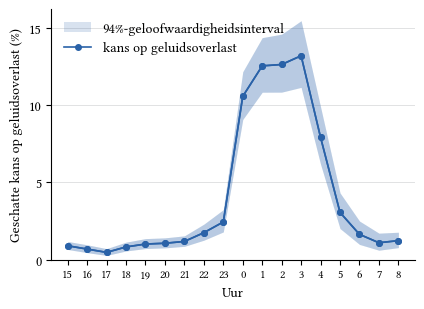

In [30]:
NACHTBLAUW = KLEUR_NACHT

plot_df = resultaten_h.set_index('uur').loc[nacht_uren]
x = np.arange(len(nacht_uren))

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 3.2))
ax.fill_between(x, plot_df['onder'], plot_df['boven'], color=NACHTBLAUW, alpha=0.18, linewidth=0)
ax.plot(x, plot_df['gemiddelde'], color=NACHTBLAUW, lw=1.2, marker='o', ms=4)

ax.set_xticks(x, [str(u) for u in nacht_uren], fontsize=CORPS_KLEIN)
ax.set_xlabel('Uur')
ax.set_ylabel('Geschatte kans op geluidsoverlast (%)')
ax.set_ylim(0, None)
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.fill_between(x, plot_df['onder'], plot_df['boven'], color=NACHTBLAUW, alpha=0.18, linewidth=0,
                label='94%-geloofwaardigheidsinterval')
ax.plot(x, plot_df['gemiddelde'], color=NACHTBLAUW, lw=1.2, marker='o', ms=4,
        label='kans op geluidsoverlast')
ax.legend(frameon=False, fontsize=CORPS, loc='upper left')

fig.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig('../../fig/H8/8.6_uurverloop_multilevel.png', dpi=300, bbox_inches='tight')
#fig.savefig('../../fig/H8/8.6_uurverloop_multilevel.pdf', bbox_inches='tight')
plt.show()

In [31]:
PERIODES = {'1876–1900': KLEUR_VROEG, '1901–1913': KLEUR_MIDDEN, '1919–1939': KLEUR_LAAT}
TOON = [21, 22, 23, 0, 1, 2, 3, 4, 5, 6]

d_periode = d_hier.assign(periode=pd.cut(d_hier['year'], [1875, 1900, 1913, 1918, 1939],
                                         labels=[*list(PERIODES)[:2], 'WOI', list(PERIODES)[2]]))
d_periode = d_periode[(d_periode['periode'] != 'WOI')
                      & ~pd.to_numeric(d_periode['district'], errors='coerce').isin([8, 9])]

telling = (d_periode[d_periode['uur'].isin(TOON)]
           .groupby(['periode', 'uur'], observed=True)['is_geluid'].agg(k='sum', n='size')
           .unstack('periode').reindex(TOON).fillna(0))

# Posterieure kans per uur en periode: Beta(1 + k, 1 + n - k)
rng = np.random.default_rng(42)
posterior = {per: rng.beta(1 + telling[('k', per)], 1 + telling[('n', per)] - telling[('k', per)],
                           size=(4000, len(TOON))) * 100
             for per in PERIODES}

for per, p in posterior.items():
    verhouding = p[:, TOON.index(3)] / p[:, [TOON.index(u) for u in (0, 1, 2)]].mean(axis=1)
    print(f"{per}: n={telling[('k', per)].sum():.0f}, N={telling[('n', per)].sum():.0f} | "
          f"verhouding 3u/0–2u: {np.median(verhouding):.2f} "
          f"[{np.percentile(verhouding, 3):.2f}–{np.percentile(verhouding, 97):.2f}]")

1876–1900: n=736, N=7872 | verhouding 3u/0–2u: 0.95 [0.77–1.14]
1901–1913: n=173, N=2449 | verhouding 3u/0–2u: 1.42 [0.96–2.04]
1919–1939: n=617, N=11216 | verhouding 3u/0–2u: 1.10 [0.88–1.35]


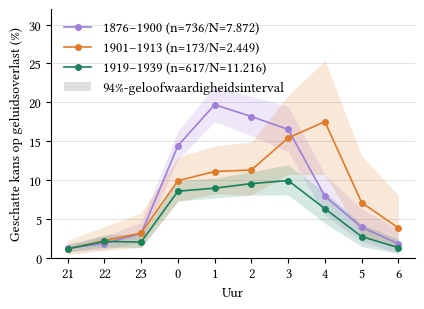

In [32]:
x = np.arange(len(TOON))

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 3.2))
for per, kleur in PERIODES.items():
    laag, hoog = np.percentile(posterior[per], [3, 97], axis=0)
    mid = posterior[per].mean(axis=0)
    k, n = telling[('k', per)].sum(), telling[('n', per)].sum()
    ax.fill_between(x, laag, hoog, color=kleur, alpha=0.18, linewidth=0)
    ax.plot(x, mid, color=kleur, lw=1.2, marker='o', ms=4,
            label=f'{per} (n={k:,.0f}/N={n:,.0f})'.replace(',', '.'))

ax.set_xticks(x, [str(u) for u in TOON])
ax.set_xlabel('Uur')
ax.set_ylabel('Geschatte kans op geluidsoverlast (%)')
ax.set_ylim(0, 32)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor='0.5', alpha=0.25, label='94%-geloofwaardigheidsinterval'))
ax.legend(handles=handles, frameon=False, fontsize=CORPS, loc='upper left')
fig.tight_layout()
pas_breedte_aan(fig, tight=True)
fig.savefig('../../fig/H8/8.7_uurverloop_periodes.png', dpi=300, bbox_inches='tight')
#fig.savefig('../../fig/H8/8.7_uurverloop_periodes.pdf', bbox_inches='tight')
plt.show()


In [33]:
TERMEN = ["dronken", "dronkenschap", "dronkaard", "beschonken", "zatlap", "zatte"]
PATROON = re.compile(r"\b(dronk\w*|beschonken|zatlap\w*|zatte\w*)\b")


def zoek_dronkenschap(tekst, drempel=88):
    tekst = str(tekst).lower()
    woorden = re.findall(r"[a-z]{6,}", tekst)
    fuzzy = [w for w in woorden
             if not w.startswith("ge")
             and any(fuzz.ratio(w, t) >= drempel for t in TERMEN)]
    return sorted(set(PATROON.findall(tekst)) | set(fuzzy))


df_geluid["drank_termen"] = df_geluid["text"].apply(zoek_dronkenschap)
df_geluid["dronkenschap"] = df_geluid["drank_termen"].str.len() > 0

n = df_geluid["dronkenschap"].sum()
print(f"{n} van {len(df_geluid)} gebeurtenissen ({n / len(df_geluid):.1%})")


1826 van 8202 gebeurtenissen (22.3%)


In [34]:
from scipy.stats import chi2_contingency

voor = df_geluid[df_geluid["year"].between(1882, 1886)]
na = df_geluid[df_geluid["year"].between(1888, 1892)]

tabel = [[voor["dronkenschap"].sum(), (~voor["dronkenschap"]).sum()],
         [na["dronkenschap"].sum(), (~na["dronkenschap"]).sum()]]
chi2, p, *_ = chi2_contingency(tabel)
v = (chi2 / (len(voor) + len(na))) ** 0.5

print(f"voor: {voor['dronkenschap'].mean():.1%} (n={len(voor)}) | "
      f"na: {na['dronkenschap'].mean():.1%} (n={len(na)}) | p={p:.3f}, V={v:.3f}")

voor: 15.1% (n=649) | na: 30.9% (n=703) | p=0.000, V=0.185


In [35]:
for wijk, groep in df_geluid[df_geluid["year"].between(1882, 1892)].groupby("district"):
    v, n = groep[groep["year"] < 1887], groep[groep["year"] > 1887]
    print(f"wijk {wijk}: {v['dronkenschap'].mean():.1%} (n={len(v)}) → "
          f"{n['dronkenschap'].mean():.1%} (n={len(n)})")

wijk 1: 0.0% (n=72) → 28.7% (n=272)
wijk 3: 17.0% (n=577) → 33.7% (n=374)
wijk 8: nan% (n=0) → 22.8% (n=57)


In [36]:
rijen = []
for breuk in range(1882, 1936):
    v = df_geluid[df_geluid["year"].between(breuk - 5, breuk - 1)]["dronkenschap"]
    n = df_geluid[df_geluid["year"].between(breuk + 1, breuk + 5)]["dronkenschap"]
    if len(v) >= 100 and len(n) >= 100:
        rijen.append((breuk, n.mean() - v.mean()))

sprongen = pd.DataFrame(rijen, columns=["breukjaar", "verschil"]).sort_values("verschil", ascending=False)
print(sprongen.head(10).to_string(index=False, float_format="{:+.1%}".format))

 breukjaar  verschil
      1886    +17.5%
      1887    +15.8%
      1885    +13.4%
      1884    +12.3%
      1903    +11.3%
      1904    +10.3%
      1905     +7.2%
      1888     +7.0%
      1921     +5.6%
      1902     +4.9%


In [37]:
w3 = df_geluid[(df_geluid["district"] == 3) & df_geluid["year"].between(1883, 1890)]
print(w3.groupby("year")["dronkenschap"].agg(["mean", "size"]).round(3))

       mean  size
year             
1883  0.162   117
1884  0.194   108
1885  0.079    89
1886  0.172   134
1887  0.401   147
1888  0.368    87
1889  0.335   161
1890  0.276    98


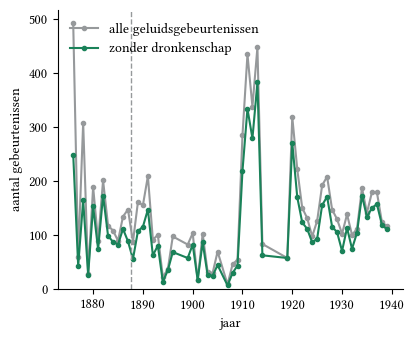

In [38]:
DONKERGROEN = KLEUR_HOOFD

per_jaar = pd.DataFrame({
    "alle geluidsgebeurtenissen": df_geluid.groupby("year").size(),
    "zonder dronkenschap": df_geluid[~df_geluid["dronkenschap"]].groupby("year").size(),
}).fillna(0)

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, 3.5))
ax.plot(per_jaar.index, per_jaar["alle geluidsgebeurtenissen"], color="#96999B", lw=1.5, marker="o", ms=3,
        label="alle geluidsgebeurtenissen")
ax.plot(per_jaar.index, per_jaar["zonder dronkenschap"], color=DONKERGROEN, lw=1.5, marker="o", ms=3,
        label="zonder dronkenschap")
ax.axvline(1887.6, color="#96999B", ls="--", lw=1)

ax.set_xlabel("jaar")
ax.set_ylabel("aantal gebeurtenissen")
ax.set_ylim(0, None)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=CORPS, loc="upper left")
fig.tight_layout()
plt.show()

In [39]:
print(df_geluid[df_geluid["year"].between(1905, 1916)]
      .groupby(["year", "district"]).size().unstack(fill_value=0))

district    3   6    9
year                  
1905        0  69    0
1907        0   8    0
1908        0  45    0
1909        0  54    0
1910        0   5  280
1911        0  13  422
1912       74   0  264
1913      118  50  280
1914       83   0    0


In [40]:
# ── Seizoen en geluidsoverlast (§8.3, voetnoot 66) ──────────────────────────
# Nacht hier op basis van het uur (21u–3u), niet van zonsondergang: nachten
# zijn in de winter langer, wat de toets anders zou vertekenen.
from scipy.stats import chi2_contingency

SEIZOEN = {12: "winter", 1: "winter", 2: "winter", 3: "lente", 4: "lente", 5: "lente",
           6: "zomer", 7: "zomer", 8: "zomer", 9: "herfst", 10: "herfst", 11: "herfst"}
NACHTUREN = [21, 22, 23, 0, 1, 2]

s = df_unique.copy()
s["uur"] = pd.to_numeric(s["E_TIME_clean"].astype(str).str.extract(r"^(\d{1,2}):")[0], errors="coerce")
s["seizoen"] = pd.to_datetime(s["E_DATE_clean"], errors="coerce", dayfirst=True).dt.month.map(SEIZOEN)
s = s[s["uur"].isin(NACHTUREN)].dropna(subset=["seizoen"])

kruis = pd.crosstab(s["seizoen"], s["is_geluid"])
chi2, p, _, _ = chi2_contingency(kruis)
n = kruis.values.sum()
print(f"N = {n:,}; chi² = {chi2:.2f}; p = {p:.3f}; Cramérs V = {(chi2 / n) ** 0.5:.3f}".replace(",", "."))
print((s.groupby("seizoen")["is_geluid"].mean() * 100).round(1).rename("% geluidsoverlast"))


N = 18.149; chi² = 6.67; p = 0.083; Cramérs V = 0.019
seizoen
herfst    7.9
lente     6.7
winter    6.6
zomer     7.1
Name: % geluidsoverlast, dtype: float64
